# 01 – Data quality audit and exploratory analysis (Cleveland)
Descriptive only. No models are fitted, no p-values are reported, and nothing here establishes statistical significance. Run from `notebooks/` or the project root; the notebook adds the project root to `sys.path`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'config.yaml').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
from src.data import eda
from src.data.loader import load_cleveland, load_config
cfg = load_config()
df = load_cleveland(config=cfg)
summary = eda.run(cfg)   # writes results/eda_*.{json,csv} and results/figures/eda_*.png
df.shape

(303, 15)

## 1. Variables
Definitions come from `data/raw/heart-disease.names`.

In [2]:
pd.Series(eda.DESCRIPTIONS, name='description').to_frame()

,description
age,age in years
sex,"1 = male, 0 = female"
cp,"chest pain type: 1 typical angina, 2 atypical ..."
trestbps,resting blood pressure on admission (mm Hg)
chol,serum cholesterol (mg/dl)
fbs,fasting blood sugar > 120 mg/dl (1 = true)
restecg,"resting ECG: 0 normal, 1 ST-T abnormality, 2 p..."
thalach,maximum heart rate achieved
exang,exercise-induced angina (1 = yes)
oldpeak,ST depression induced by exercise relative to ...


## 2. Data-quality audit

In [3]:
a = summary['audit']
print('rows:', a['n_rows'], '| duplicates:', a['duplicates'])
print('missing:', a['missing'], '| rows with missing:', a['rows_with_missing'])
print('invalid categorical values:', a['invalid_categorical'])
print('implausible continuous values:', a['implausible_continuous'], '| zero chol/trestbps:', a['zero_chol_or_trestbps'])
print('unique counts:', a['unique_counts'])
pd.DataFrame(a['ranges']).T

rows: 303 | duplicates: 0
missing: {'ca': 4, 'thal': 2} | rows with missing: [87, 166, 192, 266, 287, 302]
invalid categorical values: {}
implausible continuous values: {} | zero chol/trestbps: 0
unique counts: {'age': 41, 'sex': 2, 'cp': 4, 'trestbps': 50, 'chol': 152, 'fbs': 2, 'restecg': 3, 'thalach': 91, 'exang': 2, 'oldpeak': 40, 'slope': 3, 'ca': 4, 'thal': 3, 'num': 5, 'target': 2}


,min,max,mean,median,std
age,29.0,77.0,54.439,56.0,9.039
trestbps,94.0,200.0,131.690,130.0,17.600
chol,126.0,564.0,246.693,241.0,51.777
thalach,71.0,202.0,149.607,153.0,22.875
oldpeak,0.0,6.2,1.040,0.8,1.161


Documented value domains (e.g. `cp` in 1–4, `thal` in {3, 6, 7}) and broad plausibility bounds were checked; see the printed output for any violations. Missing values are confined to `ca` and `thal` and are **not** imputed here – imputation must be fitted inside training folds.

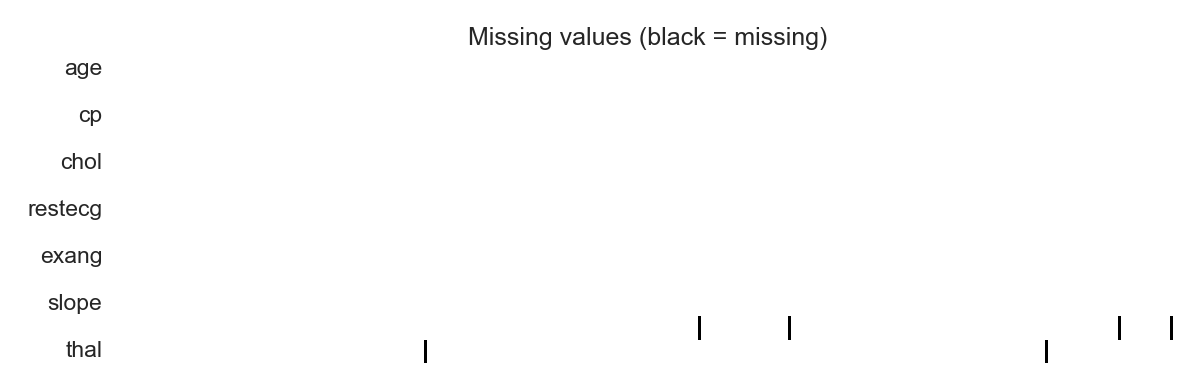

In [4]:
display(Image(str(ROOT / 'results/figures/eda_missingness.png')))

## 3. Target

In [5]:
summary['target']

{'original': {0: 164, 1: 55, 2: 36, 3: 35, 4: 13},
 'original_pct': {0: 54.1, 1: 18.2, 2: 11.9, 3: 11.6, 4: 4.3},
 'binary': {0: 164, 1: 139},
 'binary_pct': {0: 54.1, 1: 45.9},
 'minority_to_majority_ratio': 0.848}

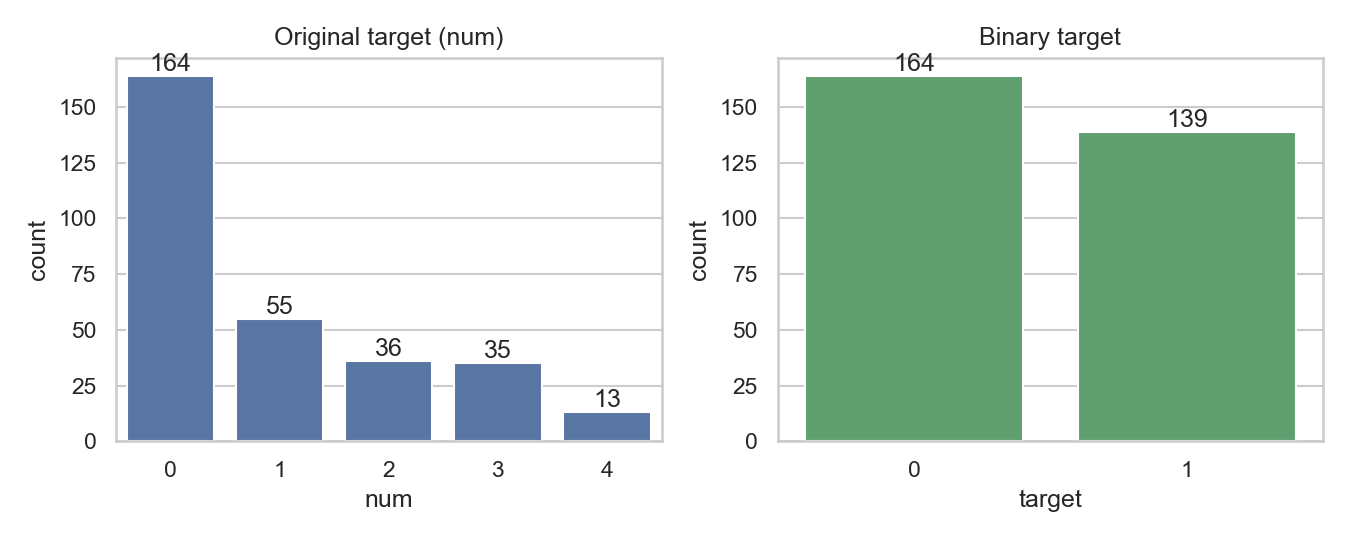

In [6]:
display(Image(str(ROOT / 'results/figures/eda_target_distribution.png')))

The original five-level target is skewed toward 0, with small counts at the severe levels (num = 4). After binarisation the classes are close to balanced (see `minority_to_majority_ratio`), so class imbalance is mild; stratification is still required for stable folds. Binarising discards severity information.

## 4. Univariate distributions

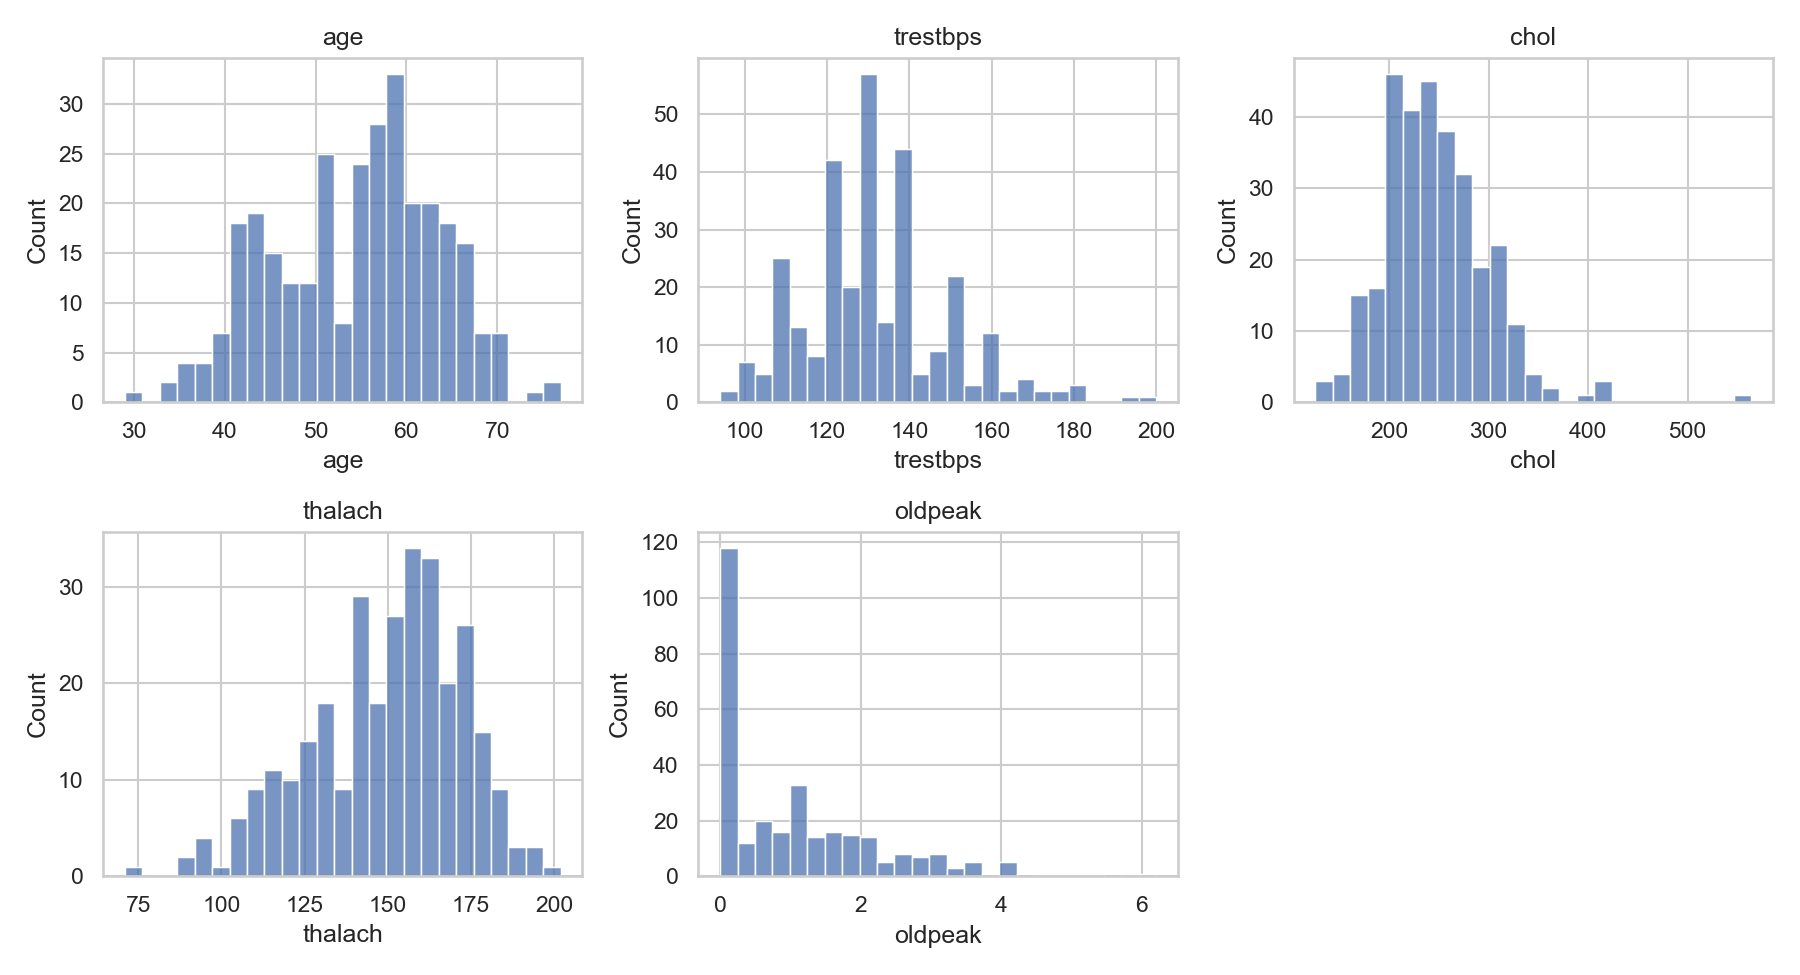

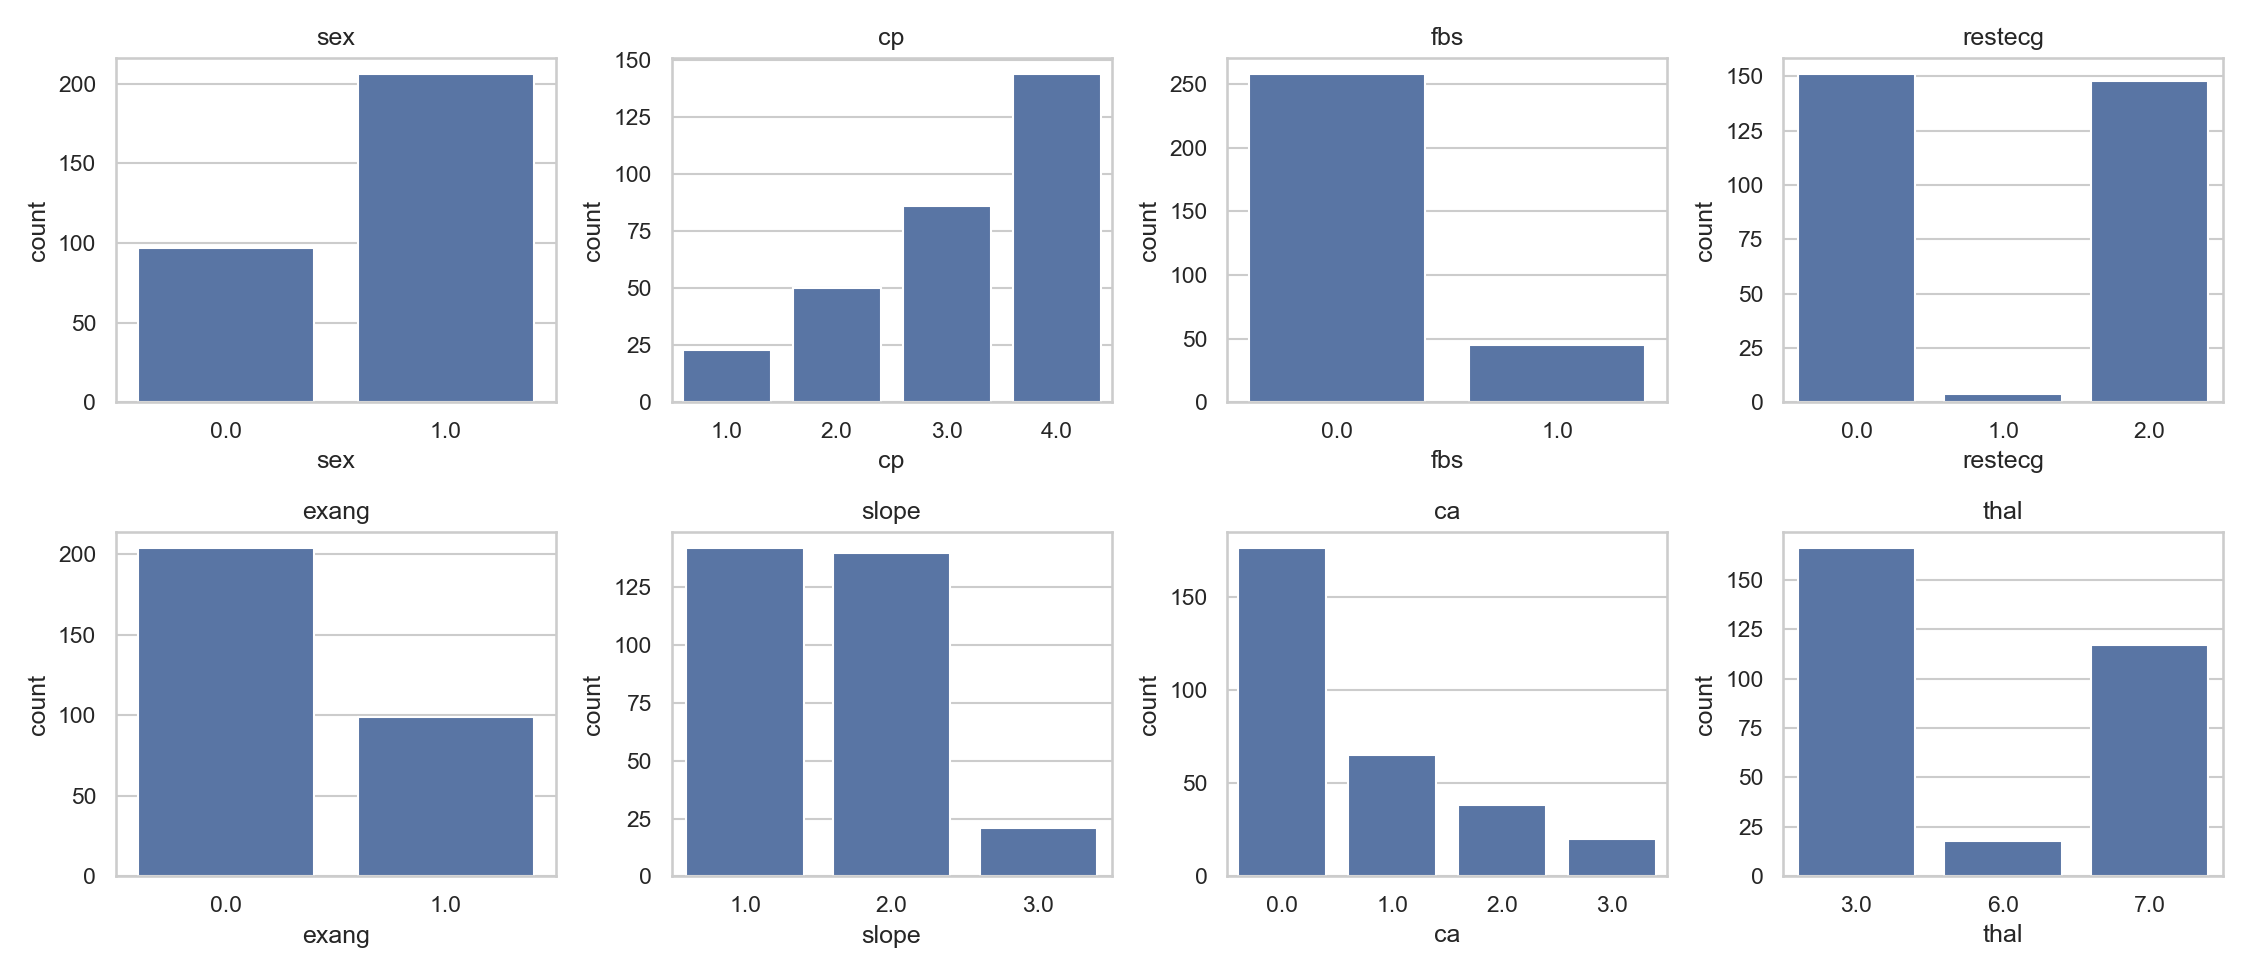

In [7]:
display(Image(str(ROOT / 'results/figures/eda_histograms.png')))
display(Image(str(ROOT / 'results/figures/eda_categorical_counts.png')))

Note the sparse level `restecg = 1` and `slope = 3`, `ca = 3`, `thal = 6`: small cells make conditional probability estimates unstable, which matters for the Bayesian models.

## 5. Features versus target (descriptive)

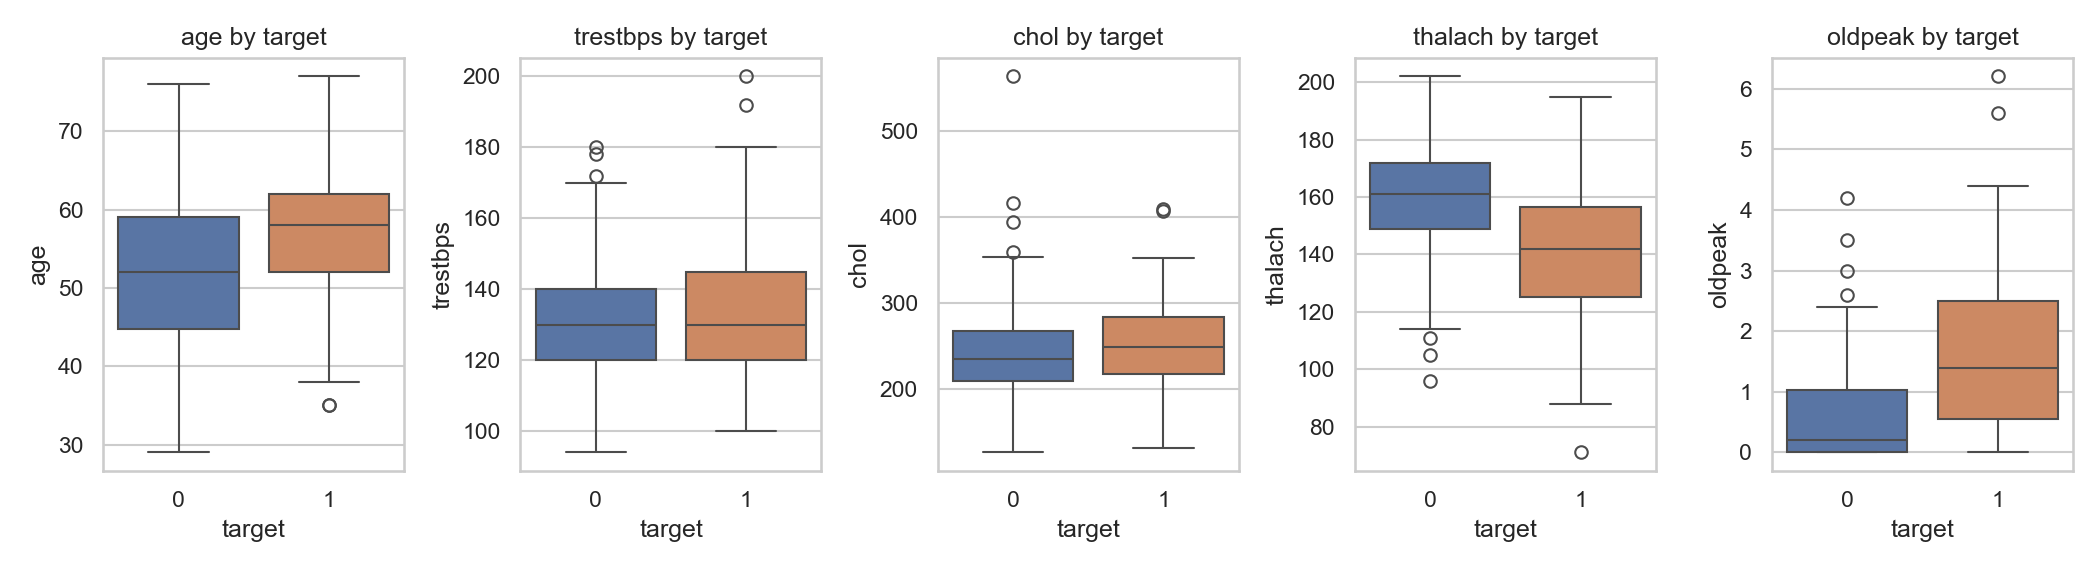

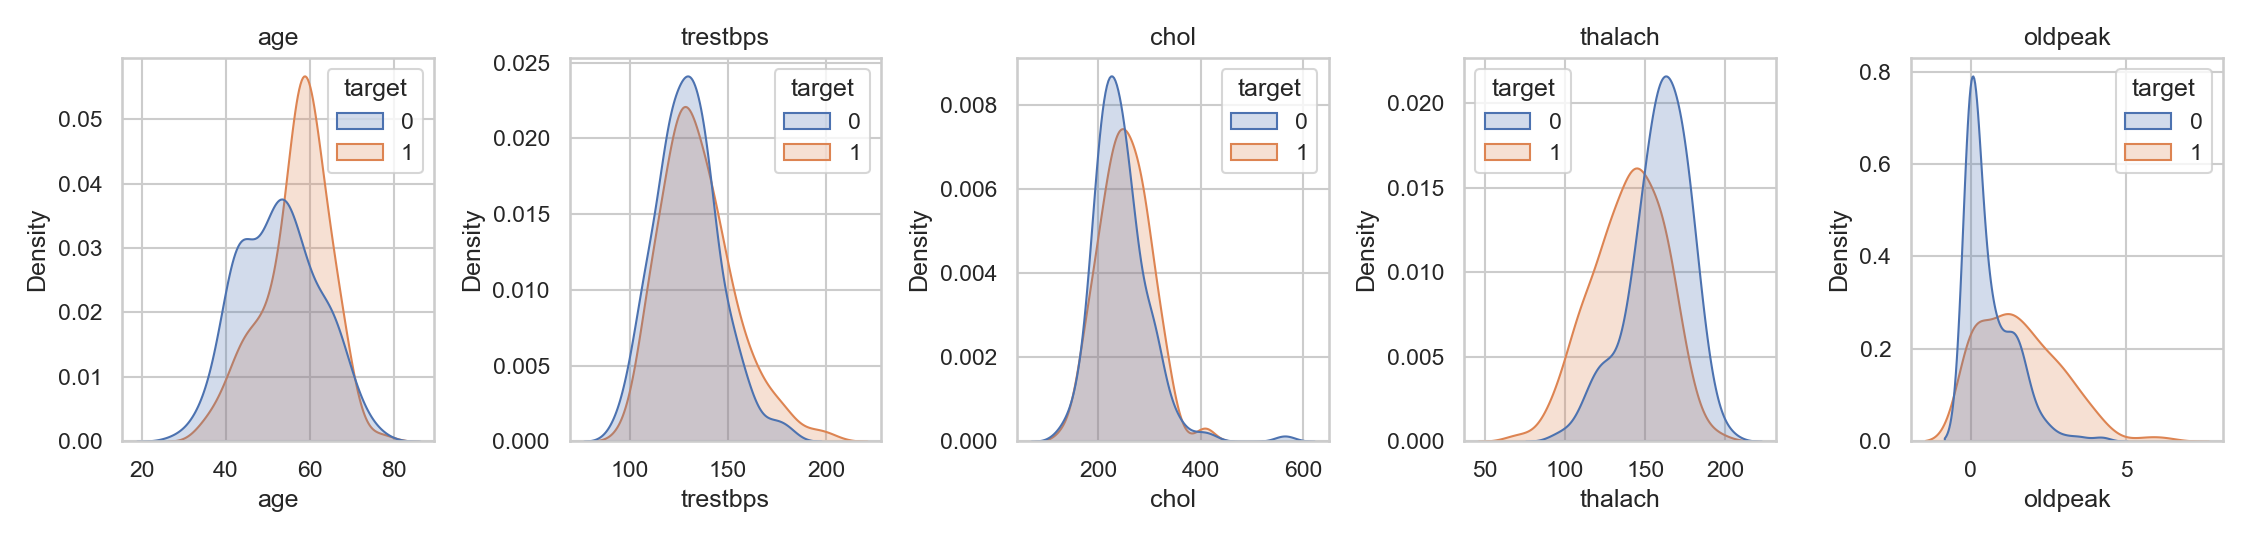

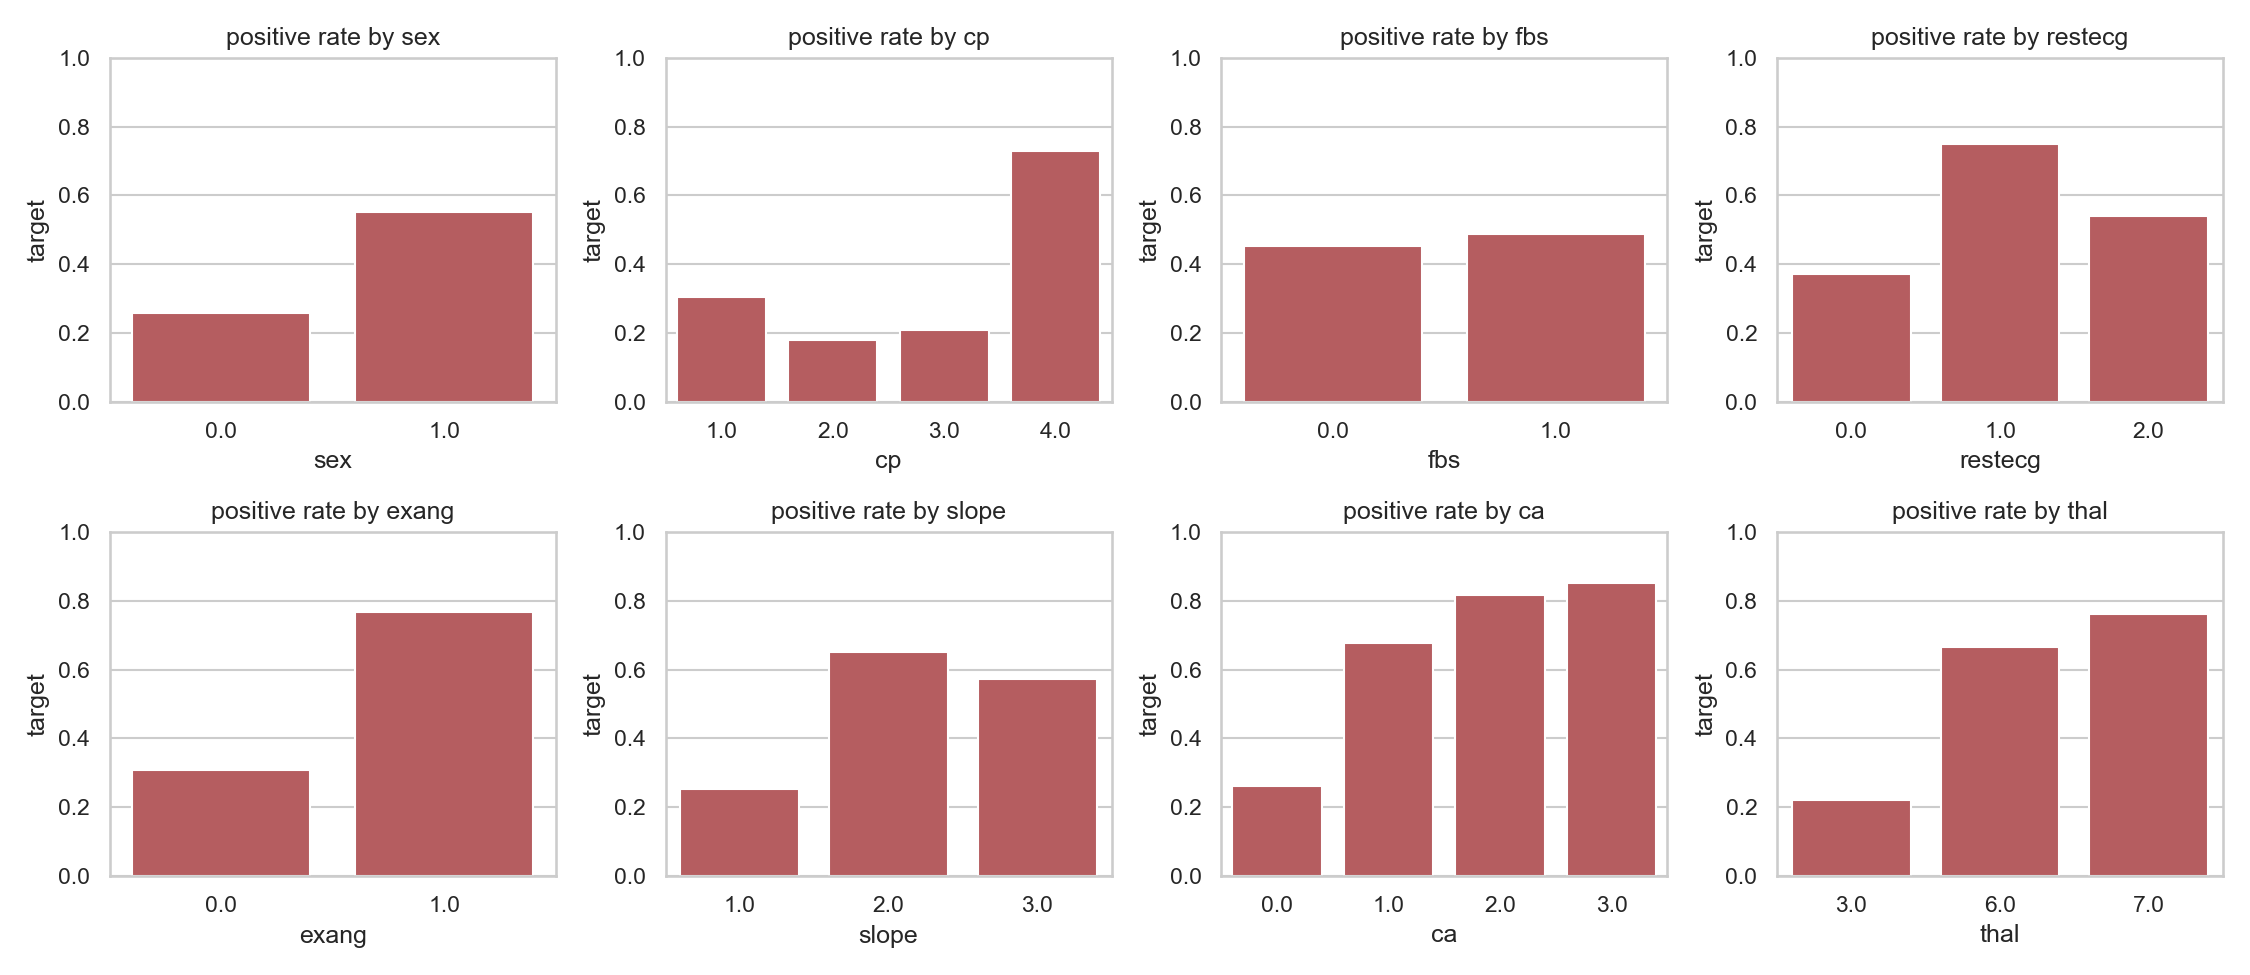

In [8]:
display(Image(str(ROOT / 'results/figures/eda_boxplots_by_target.png')))
display(Image(str(ROOT / 'results/figures/eda_continuous_by_target_kde.png')))
display(Image(str(ROOT / 'results/figures/eda_positive_rate_by_category.png')))

In [9]:
pd.read_csv(ROOT / 'results/eda_positive_rate_by_level.csv')

,feature,level,n,positive_rate
0,sex,0.0,97,0.258
1,sex,1.0,206,0.553
2,cp,1.0,23,0.304
3,cp,2.0,50,0.180
4,cp,3.0,86,0.209
5,cp,4.0,144,0.729
6,fbs,0.0,258,0.453
7,fbs,1.0,45,0.489
8,restecg,0.0,151,0.371
9,restecg,1.0,4,0.750


In [10]:
pd.Series(summary['spearman_with_binary_target'], name='spearman_with_target').sort_values()

thalach    -0.423
fbs         0.025
chol        0.121
trestbps    0.128
restecg     0.169
age         0.237
sex         0.277
slope       0.364
oldpeak     0.413
exang       0.432
cp          0.472
ca          0.489
thal        0.522
Name: spearman_with_target, dtype: float64

Spearman values are descriptive summaries on this sample only. For nominal codes (`cp`, `thal`, `restecg`, `slope`) the numeric code order is not a meaningful ranking, so these coefficients are only a rough guide; the per-level positive rates above are more informative.

## 6. Redundancy among predictors

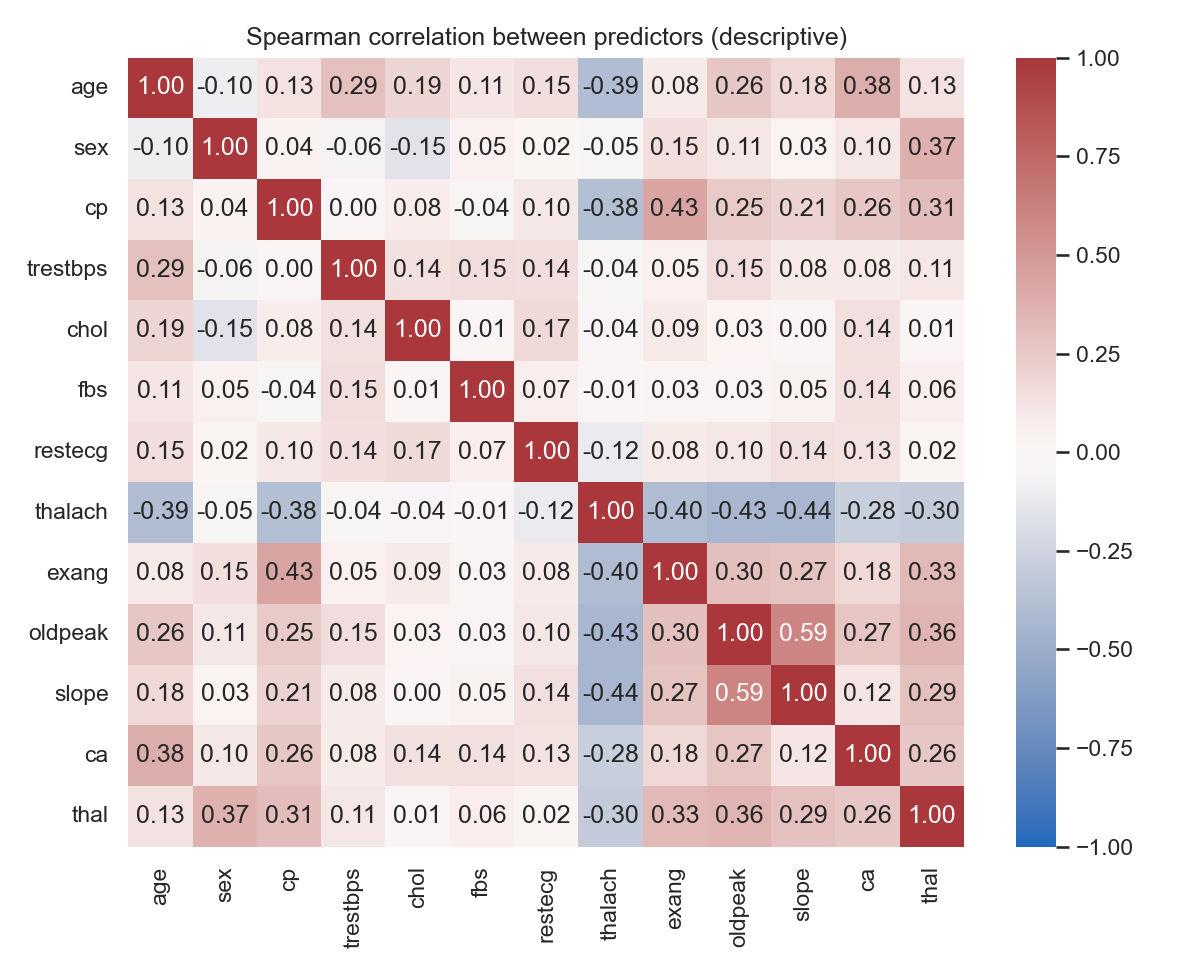

[{'a': 'oldpeak', 'b': 'slope', 'spearman': 0.595}]

In [11]:
display(Image(str(ROOT / 'results/figures/eda_correlation_heatmap.png')))
summary['redundant_pairs_abs_spearman_ge_0.5']

Only one pair reaches |Spearman| ≥ 0.5 (`oldpeak`–`slope`). `thalach` is moderately correlated with several predictors (age, cp, exang, oldpeak, slope). No predictor is a duplicate of another, so none is dropped at this stage. For Naive Bayes, correlated inputs violate conditional independence; for a Bayesian network they can be encoded as edges.

## 7. Possible leakage and validity concerns
* **Target construction.** `num` comes from coronary angiography (>50% diameter narrowing). The predictors are not derived from `num` in the 14-column file, and no identifier, date or patient-id column is present.
* **Diagnostic-pathway features.** `ca` (fluoroscopy), `thal` (thallium/radionuclide scan), `oldpeak`, `slope`, `exang` and `thalach` come from exercise/imaging work-ups that follow clinical suspicion. They are legitimate here as predictors for an academic comparison but would not be available at an initial triage, so reported performance would not transfer to such a use case.
* **Preprocessing leakage.** Imputation of `ca`/`thal`, scaling, and any discretisation must be fitted only on training folds. Nothing in this notebook fits such transformations.
* **Duplicates.** None were found, so duplicate-induced leakage across folds is not an issue.
* **Spurious asymptomatic pattern.** `cp = 4` (asymptomatic) has the highest positive rate in this sample, which is counter-intuitive and probably reflects referral and selection into catheterisation, not a protective effect of symptoms.

## 8. Correlation is not causation
A high correlation or positive rate between a feature and `target` says the two vary together in this sample. It does not show that the feature causes disease: confounders (age, sex, referral pathway), reverse relationships, and selection can all produce the same pattern. The models compared later estimate predictive associations, and the Bayesian-network edges encode assumed, not demonstrated, causal structure.

## 9. Limitations
* **Small sample:** 303 patients; 6 rows have missing values; some category levels have fewer than 25 rows. Cross-validated estimates will have wide variability.
* **Selection bias:** patients were referred for angiography at a single centre, so the sample is not representative of the general population, and prevalence (45.9% positive here) is not a population rate.
* **Single site and period:** no external validation; the data are old and possibly not representative of current practice or populations.
* **Binarisation** discards severity; `num` 1–4 are pooled.
* **Sex imbalance:** 206 male vs 97 female, limiting any subgroup conclusions.
* **Exploratory plots** here carry no inferential claims.